In [ ]:
%pip install pandas numpy scipy statsmodels matplotlib scikit-learn

import pandas as pd
import numpy as np
import scipy as sp
import statsmodels.formula.api as smf
from statsmodels.tsa.api import VAR
from statsmodels.tsa.stattools import adfuller
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.ar_model import ar_select_order
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error, mean_absolute_error
from pathlib import Path


[notice] A new release of pip is available: 24.2 -> 26.3
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [ ]:
project_dir = Path.cwd()

if project_dir.name == "jupyter":
    project_dir = project_dir.parent

data_dir = project_dir / "fred_data"

In [ ]:
macro_data_lagged = pd.read_csv(data_dir/"final_dataset_lagged.csv")

macro_data_lagged = macro_data_lagged.dropna()

macro_data_lagged["date"] = pd.to_datetime(macro_data_lagged["date"])
macro_data_lagged["date"] = macro_data_lagged["date"].dt.to_period("Q")

date_table = macro_data_lagged["date"]
macro_data_lagged = macro_data_lagged.drop(columns = "date")

diff_cols = list(macro_data_lagged.columns)

macro_data_lagged.head()

for cols in diff_cols:
    macro_data_lagged[f"{cols}_diff"] = macro_data_lagged[cols].diff()
    print(macro_data_lagged.isna().sum())

macro_data_lagged = macro_data_lagged.dropna()
macro_data_lagged = pd.concat([macro_data_lagged, date_table], axis = 1)

cpi_value                  0
ffr_value                  0
m2_value                   0
oil_price_value            0
rgdp_value                 0
unemployment_value         0
lag1_cpi_value             0
lag1_ffr_value             0
lag1_m2_value              0
lag1_oil_price_value       0
lag1_rgdp_value            0
lag1_unemployment_value    0
lag2_cpi_value             0
lag2_ffr_value             0
lag2_m2_value              0
lag2_oil_price_value       0
lag2_rgdp_value            0
lag2_unemployment_value    0
lag3_cpi_value             0
lag3_ffr_value             0
lag3_m2_value              0
lag3_oil_price_value       0
lag3_rgdp_value            0
lag3_unemployment_value    0
lag4_cpi_value             0
lag4_ffr_value             0
lag4_m2_value              0
lag4_oil_price_value       0
lag4_rgdp_value            0
lag4_unemployment_value    0
time_trend                 0
cpi_value_diff             1
dtype: int64
cpi_value                  0
ffr_value                  0
m

/var/folders/z9/zs53dpyj0ll2dnctgygq146c0000gn/T/ipykernel_52785/2974587114.py:5: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  macro_data_lagged["date"] = pd.to_datetime(macro_data_lagged["date"])


In [3]:
macro_data_lagged["covid_dummy"] = (macro_data_lagged["date"] >= pd.Period("2020Q1")) & (macro_data_lagged["date"] <= pd.Period("2023Q1"))
macro_data_lagged["covid_dummy"] = macro_data_lagged["covid_dummy"].astype(int)

macro_data_lagged["post_covid_dummy"] = (macro_data_lagged["date"] >= pd.Period("2020Q1")).astype(int)

pre_covid_l = macro_data_lagged[(macro_data_lagged["covid_dummy"] == 0) & (macro_data_lagged["post_covid_dummy"] == 0)]
covid_l = macro_data_lagged[(macro_data_lagged["covid_dummy"] == 1) & (macro_data_lagged["post_covid_dummy"] == 1)]
post_covid_l = macro_data_lagged[(macro_data_lagged["covid_dummy"] == 0) & (macro_data_lagged["post_covid_dummy"] == 1)]

In [4]:
dataset_l = [pre_covid_l, covid_l, post_covid_l]

for i, ds in enumerate(dataset_l):
    dataset_l[i] = ds.drop(columns = ["covid_dummy", "post_covid_dummy"])

    pre_covid_l, covid_l, post_covid_l = dataset_l

pre_covid_l = pre_covid_l.dropna()

pre_covid_l.head()

,cpi_value,ffr_value,m2_value,oil_price_value,rgdp_value,unemployment_value,lag1_cpi_value,lag1_ffr_value,lag1_m2_value,lag1_oil_price_value,...,lag3_rgdp_value_diff,lag3_unemployment_value_diff,lag4_cpi_value_diff,lag4_ffr_value_diff,lag4_m2_value_diff,lag4_oil_price_value_diff,lag4_rgdp_value_diff,lag4_unemployment_value_diff,time_trend_diff,date
5,113.066667,6.650000,2772.266667,19.406032,9083.256,6.266667,111.800000,6.220000,2747.933333,18.250328,...,84.077,-0.200000,-0.533333,-0.906667,67.433333,-3.351119,39.397,0.133333,1.0,1987Q2
6,114.266667,6.843333,2788.966667,20.410000,9162.024,6.000000,113.066667,6.650000,2772.266667,19.406032,...,47.592,-0.133333,0.666667,-0.713333,63.833333,-0.052187,84.077,-0.200000,1.0,1987Q3
7,115.333333,6.916667,2820.100000,18.656562,9319.332,5.833333,114.266667,6.843333,2788.966667,20.410000,...,66.174,-0.233333,0.766667,0.060000,58.366667,1.592545,47.592,-0.133333,1.0,1987Q4
8,116.233333,6.663333,2868.900000,16.685000,9367.502,5.700000,115.333333,6.916667,2820.100000,18.656562,...,96.889,-0.333333,1.333333,-0.046667,42.566667,2.843876,66.174,-0.233333,1.0,1988Q1
9,117.566667,7.156667,2925.333333,17.252813,9490.594,5.466667,116.233333,6.663333,2868.900000,16.685000,...,78.768,-0.266667,1.266667,0.430000,24.333333,1.155704,96.889,-0.333333,1.0,1988Q2


In [5]:
ar_columns = [
    col for col in pre_covid_l.columns
    if col.__contains__("cpi")
]

ar_diff_columns = [
    col for col in ar_columns
    if col.__contains__("diff")
]

ar_lag_diff_columns = [
    col for col in ar_diff_columns
    if col.__contains__("lag")
]

print(ar_diff_columns)

ar_diff_columns_n_date = ["date"] + ar_diff_columns

ar_diff_dataframe = pre_covid_l[ar_diff_columns_n_date]

ar_diff_dataframe = ar_diff_dataframe.dropna()
ar_diff_dataframe = ar_diff_dataframe.sort_values("date")

ar_diff_dataframe.head()

['cpi_value_diff', 'lag1_cpi_value_diff', 'lag2_cpi_value_diff', 'lag3_cpi_value_diff', 'lag4_cpi_value_diff']


,date,cpi_value_diff,lag1_cpi_value_diff,lag2_cpi_value_diff,lag3_cpi_value_diff,lag4_cpi_value_diff
5,1987Q2,1.266667,1.333333,0.766667,0.666667,-0.533333
6,1987Q3,1.200000,1.266667,1.333333,0.766667,0.666667
7,1987Q4,1.066667,1.200000,1.266667,1.333333,0.766667
8,1988Q1,0.900000,1.066667,1.200000,1.266667,1.333333
9,1988Q2,1.333333,0.900000,1.066667,1.200000,1.266667


In [6]:
#Adjusted R-Squared = 1 - [RSS/(n-k-1)]/[TSS/(n-1)]

formula = ' + '.join(ar_lag_diff_columns)

print(formula)

cpi_ar_model = smf.ols(f"cpi_value_diff ~ {formula}", data = ar_diff_dataframe)
cpi_ar_model_1 = smf.ols(f"cpi_value_diff ~ lag1_cpi_value_diff + lag2_cpi_value_diff", data = ar_diff_dataframe)

cpi_ar_model_fit = cpi_ar_model.fit()
cpi_ar_model_1_fit = cpi_ar_model_1.fit()

display(cpi_ar_model_fit.summary())
display(cpi_ar_model_1_fit.summary())

lag1_cpi_value_diff + lag2_cpi_value_diff + lag3_cpi_value_diff + lag4_cpi_value_diff


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:         cpi_value_diff   R-squared:                       0.072
Model:                            OLS   Adj. R-squared:                  0.042
Method:                 Least Squares   F-statistic:                     2.427
Date:                Fri, 06 Nov 2026   Prob (F-statistic):             0.0513
Time:                        09:36:49   Log-Likelihood:                -169.37
No. Observations:                 131   AIC:                             348.7
Df Residuals:                     126   BIC:                             363.1
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
=======================================================================================
                          coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------
Intercept               1.1279      0.194      5.828      0.000       0.745       1.511
lag1_cpi_value_diff     0.2306      0.089      2.591      0.011       0.054       0.407
lag2_cpi_value_diff    -0.1723      0.091     -1.886      0.062      -0.353       0.009
lag3_cpi_value_diff     0.0253      0.092      0.275      0.783      -0.156       0.207
lag4_cpi_value_diff    -0.0965      0.088     -1.093      0.276      -0.271       0.078
==============================================================================
Omnibus:                      111.385   Durbin-Watson:                   1.970
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             1882.721
Skew:                          -2.715   Prob(JB):                         0.00
Kurtosis:                      20.760   Cond. No.                         6.84
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:         cpi_value_diff   R-squared:                       0.063
Model:                            OLS   Adj. R-squared:                  0.048
Method:                 Least Squares   F-statistic:                     4.283
Date:                Fri, 06 Nov 2026   Prob (F-statistic):             0.0158
Time:                        09:36:49   Log-Likelihood:                -169.98
No. Observations:                 131   AIC:                             346.0
Df Residuals:                     128   BIC:                             354.6
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
=======================================================================================
                          coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------
Intercept               1.0331      0.146      7.086      0.000       0.745       1.322
lag1_cpi_value_diff     0.2300      0.087      2.628      0.010       0.057       0.403
lag2_cpi_value_diff    -0.1563      0.087     -1.786      0.076      -0.329       0.017
==============================================================================
Omnibus:                      116.227   Durbin-Watson:                   1.992
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             2165.777
Skew:                          -2.853   Prob(JB):                         0.00
Kurtosis:                      22.085   Cond. No.                         4.23
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [7]:
cpi_history = pre_covid_l["cpi_value_diff"]

lag1_cpi = cpi_history.iloc[-1]
lag2_cpi = cpi_history.iloc[-2]

forecast_h1 = (
    cpi_ar_model_1_fit.params["Intercept"]
    + cpi_ar_model_1_fit.params["lag1_cpi_value_diff"] * lag1_cpi
    + cpi_ar_model_1_fit.params["lag2_cpi_value_diff"] * lag2_cpi
)

print("2020Q1 Forecast:", forecast_h1)

forecast_h2 = (
    cpi_ar_model_1_fit.params["Intercept"]
    + cpi_ar_model_1_fit.params["lag1_cpi_value_diff"] * forecast_h1
    + cpi_ar_model_1_fit.params["lag2_cpi_value_diff"] * lag1_cpi
)

print("2020Q2 Forecast:", forecast_h2)

2020Q1 Forecast: 1.315229547848816
2020Q2 Forecast: 1.0545523140877238


In [8]:
forecast_horizon = 2

forecast_origins = pd.period_range(
    start="2019Q4",
    end="2023Q3",
    freq="Q"
)

forecast_dfs = []

params = cpi_ar_model_fit.params

for origin in forecast_origins:

    history = macro_data_lagged[macro_data_lagged["date"] <= origin].sort_values("date")

    # 마지막 4개 CPI 관측값
    last_observations = (history["cpi_value_diff"].iloc[-4:].to_numpy()[::-1])

    forecasts = []

    for h in range(1, forecast_horizon + 1):

        predicted = (
            params["Intercept"]
            + sum(params[f"lag{i}_cpi_value_diff"] * last_observations[i-1]
                  for i in range(1, 5)
            )
        )

        forecasts.append({
            "origin": origin,
            "target_date": origin + h,
            "horizon": h,
            "forecast": predicted
        })

        # 예측값을 다음 분기 예측에 반영
        # 예측값을 정렬의 맨 앞에 (위치: [:-1]) 배정
        last_observations = np.r_[
            predicted,
            last_observations[:-1]
        ]

    forecast_dfs.append(pd.DataFrame(forecasts))

forecast_results = pd.concat(
    forecast_dfs,
    ignore_index=True
)

display(forecast_results.head(10))

# 첫번째 관측치: 2020Q1 = 2019Q4 + 2019Q3 + 2019Q2 + 2019Q1


,origin,target_date,horizon,forecast
0,2019Q4,2020Q1,1,1.379483
1,2019Q4,2020Q2,2,0.977683
2,2020Q1,2020Q2,1,0.873974
3,2020Q1,2020Q3,2,1.133441
4,2020Q2,2020Q3,1,0.349619
5,2020Q2,2020Q4,2,1.493627
6,2020Q3,2020Q4,1,2.088484
7,2020Q3,2021Q1,2,0.951072
8,2020Q4,2021Q1,1,0.900698
9,2020Q4,2021Q2,2,1.331134


In [9]:
forecast_horizon = 2

forecast_origins = pd.period_range(
    start="2019Q4",
    end="2023Q3",
    freq="Q"
)

forecast_dfs_2 = []

params = cpi_ar_model_1_fit.params

for origin in forecast_origins:

    history = macro_data_lagged[macro_data_lagged["date"] <= origin].sort_values("date")

    # 마지막 4개 CPI 관측값
    last_observations = (history["cpi_value_diff"].iloc[-2:].to_numpy()[::-1])

    forecasts = []

    for h in range(1, forecast_horizon + 1):

        predicted = (
            params["Intercept"]
            + sum(params[f"lag{i}_cpi_value_diff"] * last_observations[i-1]
                  for i in range(1, 3)
            )
        )

        forecasts.append({
            "origin": origin,
            "target_date": origin + h,
            "horizon": h,
            "forecast": predicted
        })

        # 예측값을 다음 분기 예측에 반영
        # 예측값을 정렬의 맨 앞에 (위치: [:-1]) 배정
        last_observations = np.r_[
            predicted,
            last_observations[:-1]
        ]

    forecast_dfs_2.append(pd.DataFrame(forecasts))

forecast_results_2 = pd.concat(
    forecast_dfs_2,
    ignore_index = True
)

display(forecast_results_2.head(10))


,origin,target_date,horizon,forecast
0,2019Q4,2020Q1,1,1.315230
1,2019Q4,2020Q2,2,1.054552
2,2020Q1,2020Q2,1,0.965878
3,2020Q1,2020Q3,2,1.109999
4,2020Q2,2020Q3,1,0.306988
5,2020Q2,2020Q4,2,1.498408
6,2020Q3,2020Q4,1,2.101591
7,2020Q3,2021Q1,2,1.058671
8,2020Q4,2021Q1,1,1.005408
9,2020Q4,2021Q2,2,0.972150


In [10]:
# RMSE = sqrt(RSS)/sqrt(N)
# MAE = Var + Bias

horizon_1_results = forecast_results[forecast_results["horizon"] == 1]
horizon_1_results["date"] = horizon_1_results["target_date"]

horizon_1_results = horizon_1_results[(horizon_1_results["target_date"] >= pd.Period("2020Q1")) & (horizon_1_results["target_date"] <= pd.Period("2023Q1"))]

comparison = macro_data_lagged[(macro_data_lagged["covid_dummy"] == 1) & (macro_data_lagged["post_covid_dummy"] == 1)]
comparison = comparison.reset_index()
comparison = comparison.drop(columns = "index")

comparison_table = horizon_1_results.merge(
    comparison[["cpi_value_diff", "date"]],
    on = "date",
    how = "right"
)


rmse = np.sqrt(mean_squared_error(
        comparison_table["cpi_value_diff"],
        comparison_table["forecast"]
    ))

mae = mean_absolute_error(
        comparison_table["cpi_value_diff"],
        comparison_table["forecast"]
        )

print("RMSE for lag4, h1:", rmse)
print("MAE for lag4, h1:", mae)

RMSE for lag4, h1: 3.151855629058562
MAE for lag4, h1: 2.776587410966341


In [11]:
horizon_2_results = forecast_results[forecast_results["horizon"] == 2]
horizon_2_results["date"] = horizon_2_results["target_date"]

comparison_table_2 = horizon_2_results.merge(
    comparison[["cpi_value_diff", "date"]],
    on = "date",
    how = "inner"
)


rmse_h2 = np.sqrt(mean_squared_error(
        comparison_table_2["cpi_value_diff"],
        comparison_table_2["forecast"]
    ))

mae_h2 = mean_absolute_error(
        comparison_table_2["cpi_value_diff"],
        comparison_table_2["forecast"]
        )

print("RMSE for lag4, h2:", rmse_h2)
print("MAE for lag4, h2:", mae_h2)

RMSE for lag4, h2: 3.844923768710656
MAE for lag4, h2: 3.451395104931892


In [12]:
f2_horizon_1_results = forecast_results_2[forecast_results_2["horizon"] == 1]
f2_horizon_1_results["date"] = f2_horizon_1_results["target_date"]

f2_comparison_table_1 = f2_horizon_1_results.merge(
    comparison[["cpi_value_diff", "date"]],
    on = "date",
    how = "right"
)


f2_rmse_h1 = np.sqrt(mean_squared_error(
        f2_comparison_table_1["cpi_value_diff"],
        f2_comparison_table_1["forecast"]
    ))

f2_mae_h1 = mean_absolute_error(
        f2_comparison_table_1["cpi_value_diff"],
        f2_comparison_table_1["forecast"]
        )

print("RMSE for lag2, h1:", f2_rmse_h1)
print("MAE for lag2, h1:", f2_mae_h1)

RMSE for lag2, h1: 3.0493131528855963
MAE for lag2, h1: 2.6652461067244606


In [13]:
f2_horizon_2_results = forecast_results_2[forecast_results_2["horizon"] == 2]
f2_horizon_2_results["date"] = f2_horizon_2_results["target_date"]

f2_comparison_table_2 = f2_horizon_2_results.merge(
    comparison[["cpi_value_diff", "date"]],
    on = "date",
    how = "inner"
)

display(f2_horizon_2_results.head())

f2_rmse_h2 = np.sqrt(mean_squared_error(
        f2_comparison_table_2["cpi_value_diff"],
        f2_comparison_table_2["forecast"]
    ))

f2_mae_h2 = mean_absolute_error(
        f2_comparison_table_2["cpi_value_diff"],
        f2_comparison_table_2["forecast"]
        )

print("RMSE for lag2, h2:", f2_rmse_h2)
print("MAE for lag2, h2:", f2_mae_h2)

,origin,target_date,horizon,forecast,date
1,2019Q4,2020Q2,2,1.054552,2020Q2
3,2020Q1,2020Q3,2,1.109999,2020Q3
5,2020Q2,2020Q4,2,1.498408,2020Q4
7,2020Q3,2021Q1,2,1.058671,2021Q1
9,2020Q4,2021Q2,2,0.972150,2021Q2


RMSE for lag2, h2: 3.6998943256510817
MAE for lag2, h2: 3.308324800414473


In [ ]:
# VAR_Model.ipynb와 같은 데이터와 설정으로 VAR 예측 생성
macro_data = pd.read_csv(data_dir/"final_dataset.csv")
macro_data["date"] = pd.PeriodIndex(macro_data["date"], freq = "Q")
macro_data = macro_data.sort_values("date")

column_list = [col for col in macro_data.columns if col != "date"]

for col in column_list:
    macro_data[f"{col}_diff"] = macro_data[col].diff()

macro_data = macro_data.dropna()
pre_covid = macro_data[macro_data["date"] < pd.Period("2020Q1")]

diff_cols = [f"{col}_diff" for col in column_list]
VAR_model = VAR(pre_covid[diff_cols])
lag_selection = VAR_model.select_order(maxlags = 8)
optimal_lag = lag_selection.selected_orders["bic"]
VAR_model_fit = VAR_model.fit(optimal_lag)

forecast_horizon = 2
forecast_origins = pd.period_range(
    start = "2019Q4",
    end = "2023Q3",
    freq = "Q"
)

var_forecast_dfs = []

for origin in forecast_origins:
    history = macro_data[macro_data["date"] <= origin]
    last_observations = history[diff_cols].iloc[-optimal_lag:]

    forecast = VAR_model_fit.forecast(
        y = last_observations.to_numpy(),
        steps = forecast_horizon
    )

    forecast_dates = pd.period_range(
        start = origin + 1,
        periods = forecast_horizon,
        freq = "Q"
    )

    forecast_df = pd.DataFrame(
        forecast,
        columns = diff_cols,
        index = forecast_dates
    )

    forecast_df = forecast_df[["cpi_value_diff"]]
    forecast_df = forecast_df[forecast_df.index <= pd.Period("2023Q4")]
    forecast_df["origin"] = origin
    forecast_df["horizon"] = [
        date.ordinal - origin.ordinal for date in forecast_df.index
    ]

    var_forecast_dfs.append(forecast_df)

final_forecast = pd.concat(var_forecast_dfs)


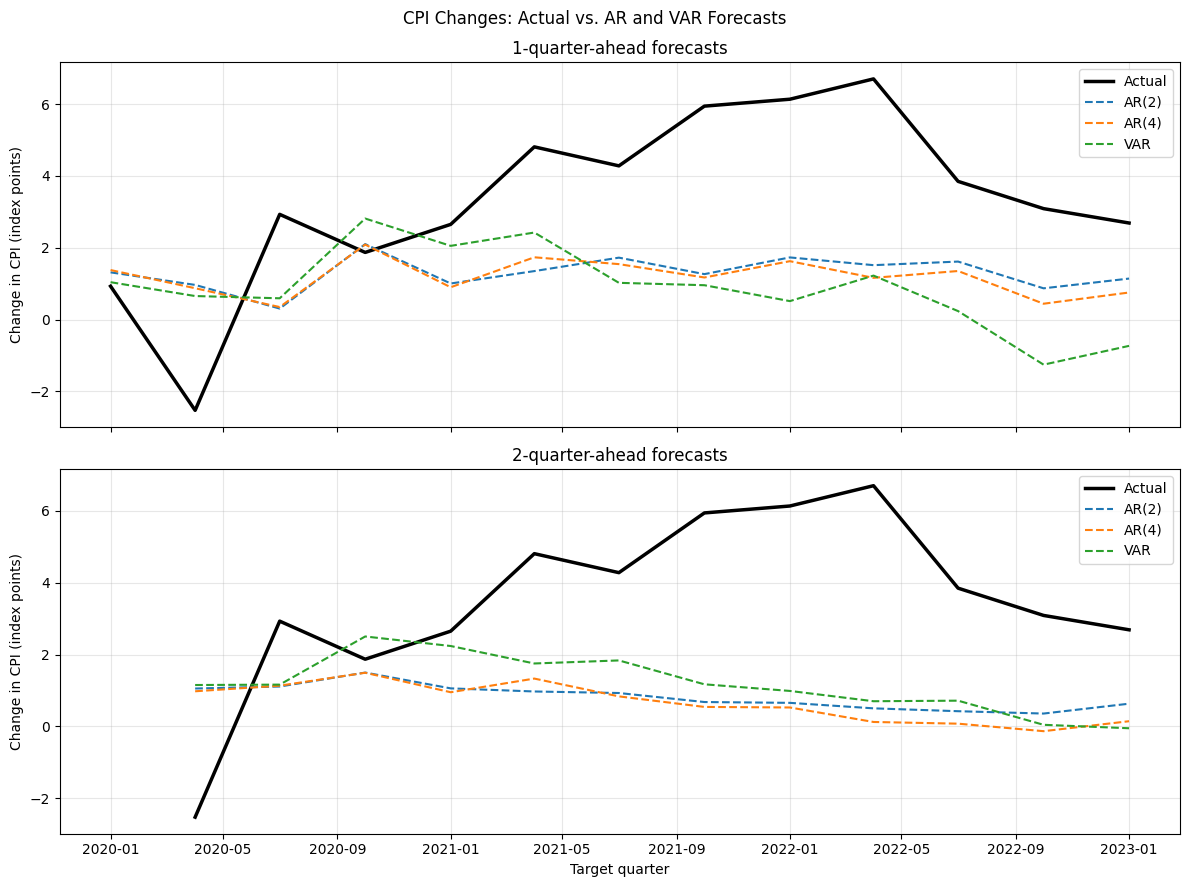

In [15]:
actual_data = macro_data_lagged[
    ["date", "cpi_value_diff"]
].dropna()

fig, axes = plt.subplots(
    nrows = 2,
    ncols = 1,
    figsize = (12, 9),
    sharex = True,
    sharey = True
)

for i, horizon in enumerate([1, 2]):

    ar2 = forecast_results_2[
        forecast_results_2["horizon"] == horizon
    ][["target_date", "forecast"]]

    ar4 = forecast_results[
        forecast_results["horizon"] == horizon
    ][["target_date", "forecast"]]

    var = final_forecast[
        final_forecast["horizon"] == horizon
    ][["cpi_value_diff"]]

    ar2 = ar2.rename(
        columns = {"target_date": "date", "forecast": "ar2"}
    )

    ar4 = ar4.rename(
        columns = {"target_date": "date", "forecast": "ar4"}
    )

    var = var.rename(columns = {"cpi_value_diff": "var"})
    var = var.rename_axis("date").reset_index()

    plot_comparison = actual_data.merge(ar2, on = "date", how = "inner")
    plot_comparison = plot_comparison.merge(ar4, on = "date", how = "inner")
    plot_comparison = plot_comparison.merge(var, on = "date", how = "inner")

    plot_comparison = plot_comparison[
        (plot_comparison["date"] >= pd.Period("2020Q1")) &
        (plot_comparison["date"] <= pd.Period("2023Q1"))
    ]

    plot_comparison = plot_comparison.sort_values("date")
    dates = plot_comparison["date"].dt.to_timestamp()

    axes[i].plot(
        dates, plot_comparison["cpi_value_diff"],
        color = "black", linewidth = 2.5, label = "Actual"
    )

    for column, label, color in [
        ("ar2", "AR(2)", "tab:blue"),
        ("ar4", "AR(4)", "tab:orange"),
        ("var", "VAR", "tab:green")
    ]:
        axes[i].plot(
            dates, plot_comparison[column],
            color = color, linestyle = "--", label = label
        )

    axes[i].set_title(f"{horizon}-quarter-ahead forecasts")
    axes[i].set_ylabel("Change in CPI (index points)")
    axes[i].grid(alpha = 0.3)
    axes[i].legend()

axes[1].set_xlabel("Target quarter")

fig.suptitle("CPI Changes: Actual vs. AR and VAR Forecasts")
fig.tight_layout()

plt.show()